Conteos por fecha y treatment_floor:

--- Fecha 20260608 ---
treatment_floor
1    3
2    3
3    3
4    3
5    3
6    3
7    3
8    3
9    3
Name: count, dtype: int64

--- Fecha 20260331 ---
treatment_floor
1    3
2    3
3    3
4    3
5    3
6    3
7    3
8    3
9    3
Name: count, dtype: int64

--- Fecha 20260622 ---
treatment_floor
1    3
2    3
3    3
4    3
5    3
6    3
7    3
8    3
9    3
Name: count, dtype: int64
----------------------------------------


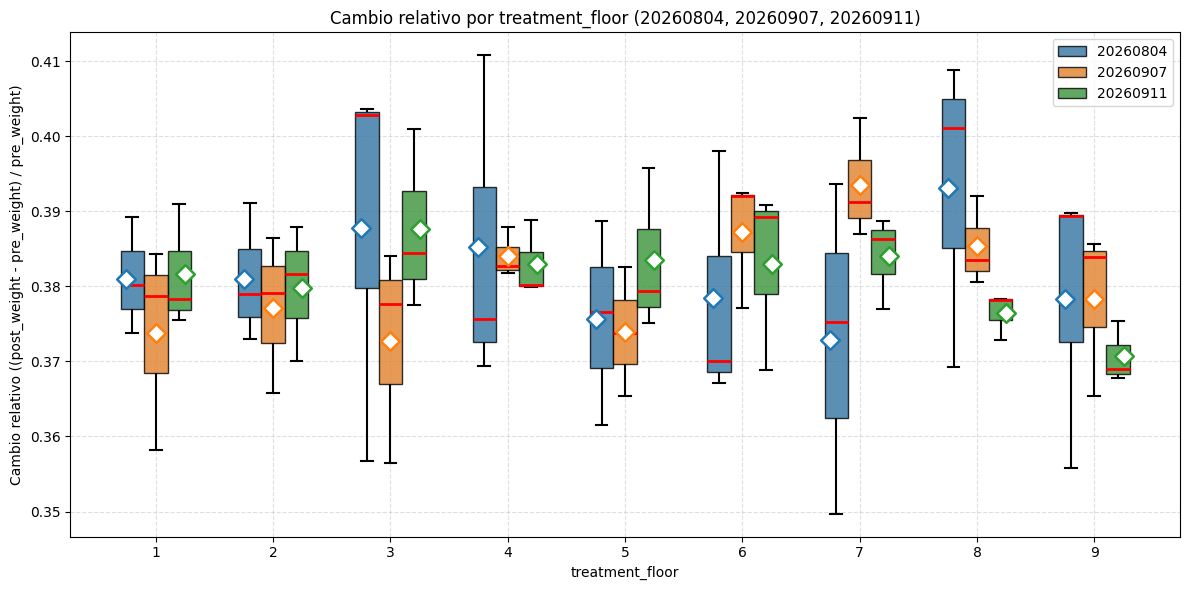

In [26]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### CERAMICA
#fechas = ["20260608", "20260331", "20260622"]

### NEODIMIO
#fechas = ["20260626", "20260721", "20260727"]

fechas = ["20260804", "20260907", "20260911"]

experiments_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments")

print("Conteos por fecha y treatment_floor:")
for f in ["20260608", "20260331", "20260622"]:
    p = experiments_dir / f / "trays.csv"
    if p.exists():
        temp_df = pd.read_csv(p)
        print(f"\n--- Fecha {f} ---")
        # Cuenta cuántos hay por cada piso y los ordena por el número de piso
        print(temp_df["treatment_floor"].value_counts().sort_index())
    else:
        print(f"\nFecha {f}: Archivo no encontrado")
print("-" * 40)

def cargar_trays(fecha, grupo_grafica):
    trays_path = experiments_dir / fecha / "trays.csv"
    if not trays_path.exists():
        raise FileNotFoundError(f"No se encontro {trays_path}")

    fecha_df = pd.read_csv(trays_path)
    fecha_df.columns = fecha_df.columns.str.strip()
    fecha_df["fecha"] = fecha
    fecha_df["grupo_grafica"] = grupo_grafica
    return fecha_df

dfs = []
for fecha in fechas:
    dfs.append(cargar_trays(fecha, fecha))

df = pd.concat(dfs, ignore_index=True)
df["treatment_floor"] = pd.to_numeric(df["treatment_floor"], errors="coerce")
df["pct_change"] = (df["post_weight"] - df["pre_weight"]) / df["pre_weight"]
control_floor = 9

grupo_order = list(fechas)
floor_order = sorted(df["treatment_floor"].dropna().unique())
palette = dict(zip(grupo_order, sns.color_palette("tab10", n_colors=len(grupo_order))))
titulo_grupos = ", ".join(fechas)

plt.figure(figsize=(12, 6))
# Boxplot por treatment_floor y fecha
sns.boxplot(
    data=df,
    x="treatment_floor",
    y="pct_change",
    hue="grupo_grafica",
    order=floor_order,
    hue_order=grupo_order,
    palette=palette,
    width=0.6,
    medianprops={"color": "red", "linewidth": 2},
    whiskerprops={"color": "k", "linewidth": 1.5},
    capprops={"color": "k", "linewidth": 1.5},
    boxprops={"alpha": 0.8, "edgecolor": "k"}
)

# Media por treatment_floor y fecha como rombo blanco
mean_df = df.groupby(["treatment_floor", "grupo_grafica"], as_index=False)["pct_change"].mean()
offsets = {grupo: 0 for grupo in grupo_order}
if len(grupo_order) > 1:
    offsets = {grupo: -0.25 + i * (0.5 / (len(grupo_order) - 1)) for i, grupo in enumerate(grupo_order)}

for grupo in grupo_order:
    grupo_means = mean_df[mean_df["grupo_grafica"] == grupo]
    x_positions = [floor_order.index(floor) + offsets[grupo] for floor in grupo_means["treatment_floor"]]
    plt.scatter(
        x_positions,
        grupo_means["pct_change"],
        marker="D",
        s=90,
        facecolors="white",
        edgecolors=palette[grupo],
        linewidths=1.8,
        zorder=10,
    )

plt.xlabel("treatment_floor")
plt.ylabel("Cambio relativo ((post_weight - pre_weight) / pre_weight)")
plt.title(f"Cambio relativo por treatment_floor ({titulo_grupos})")
plt.xticks(range(len(floor_order)), floor_order)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

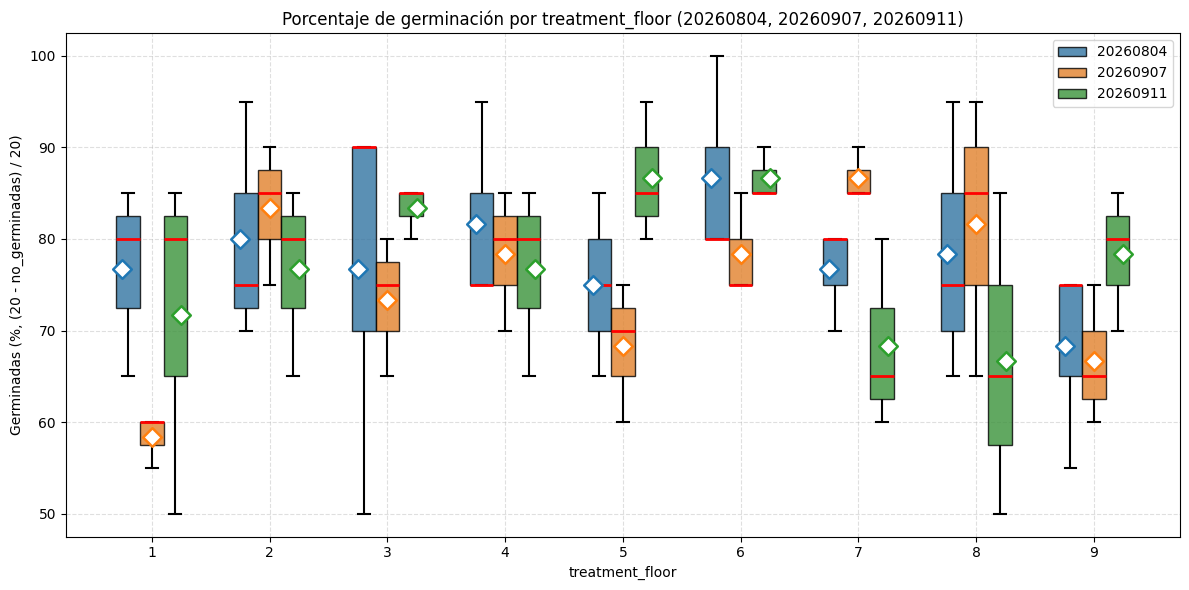

In [27]:
if "no_germinadas" in df.columns and df["no_germinadas"].notna().any():
    germ_df = df.dropna(subset=["no_germinadas"]).copy()
    # no_germinadas = semillas que NO germinaron -> se grafica el % germinado real
    germ_df["pct_germinadas"] = (20 - germ_df["no_germinadas"]) / 20 * 100

    germ_floor_order = sorted(germ_df["treatment_floor"].dropna().unique())
    germ_grupo_order = [g for g in grupo_order if g in germ_df["grupo_grafica"].unique()]

    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=germ_df,
        x="treatment_floor",
        y="pct_germinadas",
        hue="grupo_grafica",
        order=germ_floor_order,
        hue_order=germ_grupo_order,
        palette=palette,
        width=0.6,
        medianprops={"color": "red", "linewidth": 2},
        whiskerprops={"color": "k", "linewidth": 1.5},
        capprops={"color": "k", "linewidth": 1.5},
        boxprops={"alpha": 0.8, "edgecolor": "k"},
    )

    germ_mean_df = germ_df.groupby(["treatment_floor", "grupo_grafica"], as_index=False)["pct_germinadas"].mean()
    germ_offsets = {grupo: 0 for grupo in germ_grupo_order}
    if len(germ_grupo_order) > 1:
        germ_offsets = {grupo: -0.25 + i * (0.5 / (len(germ_grupo_order) - 1)) for i, grupo in enumerate(germ_grupo_order)}

    for grupo in germ_grupo_order:
        grupo_means = germ_mean_df[germ_mean_df["grupo_grafica"] == grupo]
        x_positions = [germ_floor_order.index(floor) + germ_offsets[grupo] for floor in grupo_means["treatment_floor"]]
        plt.scatter(
            x_positions,
            grupo_means["pct_germinadas"],
            marker="D",
            s=90,
            facecolors="white",
            edgecolors=palette[grupo],
            linewidths=1.8,
            zorder=10,
        )

    plt.xlabel("treatment_floor")
    plt.ylabel("Germinadas (%, (20 - no_germinadas) / 20)")
    plt.title(f"Porcentaje de germinación por treatment_floor ({titulo_grupos})")
    plt.xticks(range(len(germ_floor_order)), germ_floor_order)
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()
else:
    print("No hay datos de 'no_germinadas' disponibles para las fechas seleccionadas (fechas):", fechas)


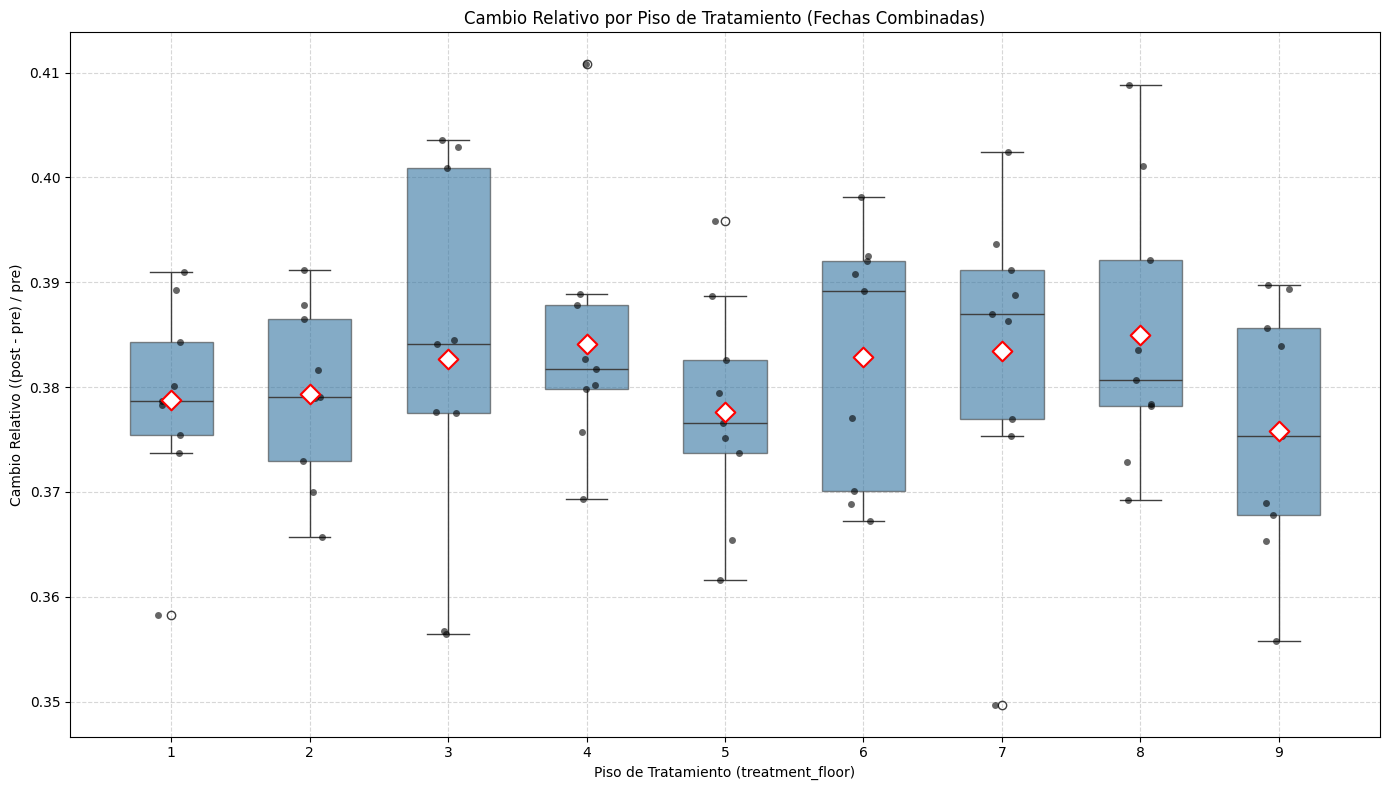

In [28]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

experiments_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments")

#### GRAFICA DE COMPARATIVA DE EXPERIMENTO
# Usa las fechas definidas en la primera celda
fechas_validas = fechas

all_dfs = []
for fecha in fechas_validas:
    trays_path = experiments_dir / fecha / "trays.csv"
    if trays_path.exists():
        raw_df = pd.read_csv(trays_path)
        raw_df.columns = raw_df.columns.str.strip()
        raw_df['fecha'] = fecha
        all_dfs.append(raw_df)
    else:
        print(f"Advertencia: No se encontró el archivo para la fecha {fecha}")

if all_dfs:
    combined_df = pd.concat(all_dfs, ignore_index=True)
    combined_df["treatment_floor"] = pd.to_numeric(combined_df["treatment_floor"], errors="coerce")
    combined_df = combined_df.dropna(subset=['treatment_floor'])
    combined_df["pct_change"] = (combined_df["post_weight"] - combined_df["pre_weight"]) / combined_df["pre_weight"]

    floor_order = sorted(combined_df["treatment_floor"].unique())

    plt.figure(figsize=(14, 8))

    # Boxplot para ver la distribución completa, agrupando todas las fechas por piso
    sns.boxplot(
        data=combined_df,
        x="treatment_floor",
        y="pct_change",
        order=floor_order,
        width=0.6,
        boxprops={'alpha':0.6}
    )

    # Stripplot para ver los puntos individuales (todas las fechas combinadas)
    sns.stripplot(
        data=combined_df,
        x='treatment_floor',
        y='pct_change',
        order=floor_order,
        color='black',
        alpha=0.6,
        jitter=True,
    )

    # Marcador para la media de cada piso (todas las fechas combinadas)
    mean_df = combined_df.groupby("treatment_floor", as_index=False)["pct_change"].mean()

    x_positions = {floor: i for i, floor in enumerate(floor_order)}
    x_pos = [x_positions[floor] for floor in mean_df["treatment_floor"]]
    plt.scatter(
        x=x_pos,
        y=mean_df["pct_change"],
        marker='D',
        s=100,
        facecolors='white',
        edgecolors='red',
        linewidths=1.5,
        zorder=10,
    )

    plt.xlabel("Piso de Tratamiento (treatment_floor)")
    plt.ylabel("Cambio Relativo ((post - pre) / pre)")
    plt.title("Cambio Relativo por Piso de Tratamiento (Fechas Combinadas)")
    plt.xticks(ticks=range(len(floor_order)), labels=floor_order)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("No se encontraron datos de experimentos para las fechas indicadas.")

In [29]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

import scipy.stats as stats

# FIX: Use combined_df from the previous cell which contains ALL experiment data,
# preventing issues from other cells filtering the global 'df'.
control_floor = 9 # Ensure control_floor is defined
df_floor = combined_df[combined_df["treatment_floor"].isin(range(1, control_floor + 1))].copy()

# Ensure 'pct_change' is calculated if it wasn't already on combined_df
if 'pct_change' not in df_floor.columns:
    df_floor["pct_change"] = (df_floor["post_weight"] - df_floor["pre_weight"]) / df_floor["pre_weight"]

df_floor = df_floor.dropna(subset=["pct_change", "treatment_floor"])
df_floor["treatment_floor"] = df_floor["treatment_floor"].astype(int)

print("Verificación de datos en el DataFrame combinado:")
print(df_floor[["treatment_floor", "floor"]].value_counts().sort_index())

print("Resumen por treatment_floor:")
print(df_floor.groupby("treatment_floor")["pct_change"].agg(["count", "mean", "std"]))
print()

modelo_floor = ols("pct_change ~ C(treatment_floor)", data=df_floor).fit()
anova_result = anova_lm(modelo_floor, typ=2)
print("ANOVA unidireccional para treatment_floor:")
print(anova_result)
print()

tukey = pairwise_tukeyhsd(df_floor["pct_change"], df_floor["treatment_floor"], alpha=0.05)
tukey_df = pd.DataFrame(tukey._results_table.data[1:], columns=tukey._results_table.data[0])
print("Comparaciones múltiples con Tukey HSD:")
print(tukey_df)
print()

control_pairs = tukey_df[
    (tukey_df["group1"] == control_floor) | (tukey_df["group2"] == control_floor)
]
print("Comparaciones Tukey HSD vs control floor 9:")
print(control_pairs)
print()

control_vals = df_floor.loc[df_floor["treatment_floor"] == control_floor, "pct_change"]
pairwise_results = []
for floor in range(1, control_floor):
    floor_vals = df_floor.loc[df_floor["treatment_floor"] == floor, "pct_change"]
    t_stat, p_val = stats.ttest_ind(floor_vals, control_vals, equal_var=False, nan_policy="omit")
    pairwise_results.append({"floor": floor, "t_stat": t_stat, "p_val": p_val})

p_vals = [x["p_val"] for x in pairwise_results]
# Filter out nan p-values before passing to multipletests
valid_indices = [i for i, p in enumerate(p_vals) if not pd.isna(p)]
p_vals_to_test = [p for p in p_vals if not pd.isna(p)]

if p_vals_to_test:
    _, p_adj, _, _ = multipletests(p_vals_to_test, method="holm")
    p_adj_full = [None] * len(p_vals)
    for i, adj_p in zip(valid_indices, p_adj):
        p_adj_full[i] = adj_p
else:
    p_adj_full = [None] * len(p_vals)


print("Pruebas por pares (tratamiento vs control floor 9) con corrección Holm:")
for i, (res, padj) in enumerate(zip(pairwise_results, p_adj_full)):
    # Check if there was data to compare
    if pd.isna(res['p_val']):
        print(f"floor {res['floor']} vs {control_floor}: No data for comparison or control is empty")
    else:
        print(
            f"floor {res['floor']} vs {control_floor}: "
            f"t={res['t_stat']:.4f}, p={res['p_val']:.4e}, p_holm={padj:.4e}"
        )

Verificación de datos en el DataFrame combinado:
treatment_floor  floor
1                A        3
                 B        3
                 C        3
2                A        3
                 B        3
                 C        3
3                A        3
                 B        3
                 C        3
4                A        3
                 B        3
                 C        3
5                A        3
                 B        3
                 C        3
6                A        3
                 B        3
                 C        3
7                A        3
                 B        3
                 C        3
8                A        3
                 B        3
                 C        3
9                A        3
                 B        3
                 C        3
Name: count, dtype: int64
Resumen por treatment_floor:
                 count      mean       std
treatment_floor                           
1                    9  0.37878

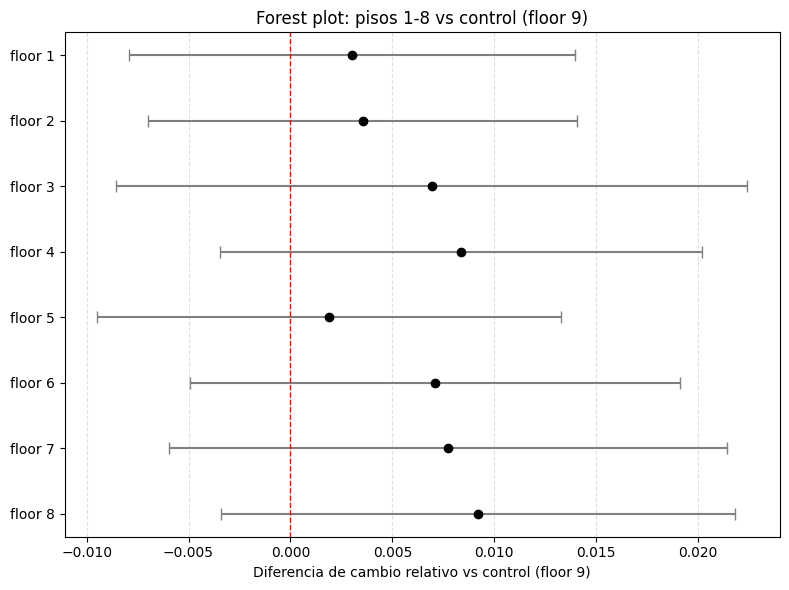

In [30]:
from statsmodels.stats.weightstats import CompareMeans, DescrStatsW
import matplotlib.pyplot as plt

# Forest plot: diferencia de medias (pct_change) de cada piso vs el control (floor 9),
# con IC 95% (Welch, mismo supuesto que el t-test por pares de arriba)
control_vals = df_floor.loc[df_floor["treatment_floor"] == control_floor, "pct_change"]

forest_rows = []
for floor in range(1, control_floor):
    floor_vals = df_floor.loc[df_floor["treatment_floor"] == floor, "pct_change"]
    cm = CompareMeans(DescrStatsW(floor_vals), DescrStatsW(control_vals))
    diff = floor_vals.mean() - control_vals.mean()
    ci_low, ci_high = cm.tconfint_diff(alpha=0.05, usevar="unequal")
    forest_rows.append({"floor": floor, "diff": diff, "ci_low": ci_low, "ci_high": ci_high})

forest_df = pd.DataFrame(forest_rows)

plt.figure(figsize=(8, 6))
plt.errorbar(
    forest_df["diff"],
    forest_df["floor"],
    xerr=[forest_df["diff"] - forest_df["ci_low"], forest_df["ci_high"] - forest_df["diff"]],
    fmt="o",
    color="black",
    ecolor="gray",
    elinewidth=1.5,
    capsize=4,
    markersize=6,
)
plt.axvline(0, color="red", linestyle="--", linewidth=1)
plt.yticks(forest_df["floor"], [f"floor {f}" for f in forest_df["floor"]])
plt.gca().invert_yaxis()
plt.xlabel(f"Diferencia de cambio relativo vs control (floor {control_floor})")
plt.title("Forest plot: pisos 1-8 vs control (floor 9)")
plt.grid(True, axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

Success: test_output.png generated.


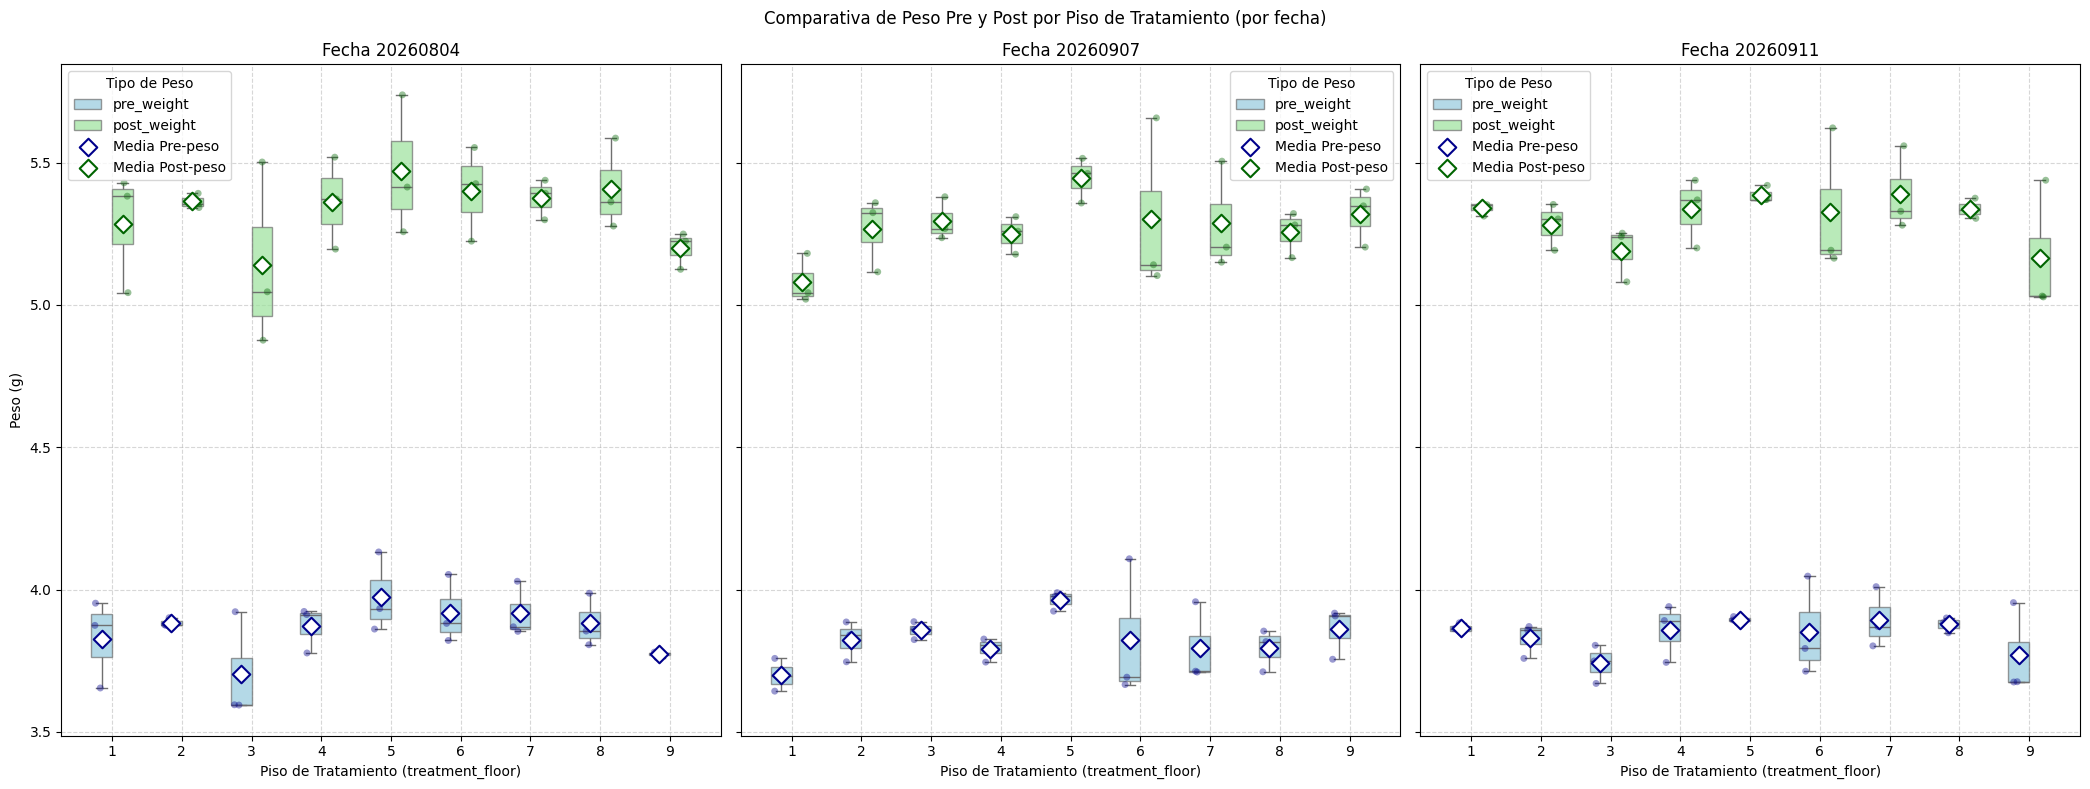

In [31]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

experiments_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments")

# Usa las fechas definidas en la primera celda
fechas_validas = fechas

all_dfs = []
for fecha in fechas_validas:
    trays_path = experiments_dir / fecha / "trays.csv"
    if trays_path.exists():
        raw_df = pd.read_csv(trays_path)
        raw_df.columns = raw_df.columns.str.strip()
        raw_df['fecha'] = fecha
        all_dfs.append(raw_df)
    else:
        print(f"Advertencia: No se encontró el archivo para la fecha {fecha}")

if all_dfs:
    combined_df = pd.concat(all_dfs, ignore_index=True)
    combined_df["treatment_floor"] = pd.to_numeric(combined_df["treatment_floor"], errors="coerce")
    combined_df = combined_df.dropna(subset=['treatment_floor'])

    # Reestructurar el DataFrame a formato largo para graficar pre y post weight en el eje y
    df_melted = pd.melt(
        combined_df,
        id_vars=["treatment_floor", "fecha"],
        value_vars=["pre_weight", "post_weight"],
        var_name="Tipo de Peso",
        value_name="Peso"
    )
    df_melted["treatment_floor"] = df_melted["treatment_floor"].astype(int)
    floor_order = sorted(df_melted["treatment_floor"].unique())
    fecha_order = [f for f in fechas_validas if f in df_melted["fecha"].unique()]

    # Un panel por fecha, para no mezclar los dos experimentos en un mismo box
    fig, axes = plt.subplots(1, len(fecha_order), figsize=(7 * len(fecha_order), 8), sharey=True)
    if len(fecha_order) == 1:
        axes = [axes]

    for ax, fecha in zip(axes, fecha_order):
        fecha_df = df_melted[df_melted["fecha"] == fecha]

        sns.boxplot(
            data=fecha_df,
            x="treatment_floor",
            y="Peso",
            hue="Tipo de Peso",
            order=floor_order,
            palette={"pre_weight": "skyblue", "post_weight": "lightgreen"},
            width=0.6,
            boxprops={'alpha': 0.7},
            ax=ax,
        )

        sns.stripplot(
            data=fecha_df,
            x="treatment_floor",
            y="Peso",
            hue="Tipo de Peso",
            order=floor_order,
            palette={"pre_weight": "darkblue", "post_weight": "darkgreen"},
            dodge=True,
            alpha=0.4,
            jitter=True,
            legend=False,
            ax=ax,
        )

        mean_df = fecha_df.groupby(["treatment_floor", "Tipo de Peso"])["Peso"].mean().reset_index()
        x_positions = {floor: i for i, floor in enumerate(floor_order)}
        mean_df['x_pos'] = mean_df['treatment_floor'].map(x_positions).astype(float)
        mean_df.loc[mean_df["Tipo de Peso"] == "pre_weight", "x_pos"] -= 0.15
        mean_df.loc[mean_df["Tipo de Peso"] == "post_weight", "x_pos"] += 0.15

        ax.scatter(
            x=mean_df[mean_df["Tipo de Peso"] == "pre_weight"]['x_pos'],
            y=mean_df[mean_df["Tipo de Peso"] == "pre_weight"]['Peso'],
            marker='D', s=80, facecolors='white', edgecolors='darkblue',
            linewidths=1.5, zorder=10, label='Media Pre-peso',
        )
        ax.scatter(
            x=mean_df[mean_df["Tipo de Peso"] == "post_weight"]['x_pos'],
            y=mean_df[mean_df["Tipo de Peso"] == "post_weight"]['Peso'],
            marker='D', s=80, facecolors='white', edgecolors='darkgreen',
            linewidths=1.5, zorder=10, label='Media Post-peso',
        )

        ax.set_xlabel("Piso de Tratamiento (treatment_floor)")
        ax.set_ylabel("Peso (g)")
        ax.set_title(f"Fecha {fecha}")
        ax.set_xticks(range(len(floor_order)))
        ax.set_xticklabels(floor_order)
        ax.grid(True, linestyle='--', alpha=0.5)
        ax.legend(title="Tipo de Peso")

    fig.suptitle("Comparativa de Peso Pre y Post por Piso de Tratamiento (por fecha)")
    plt.tight_layout()
    plt.savefig("test_output.png")
    print("Success: test_output.png generated.")
else:
    print("No se encontraron datos.")


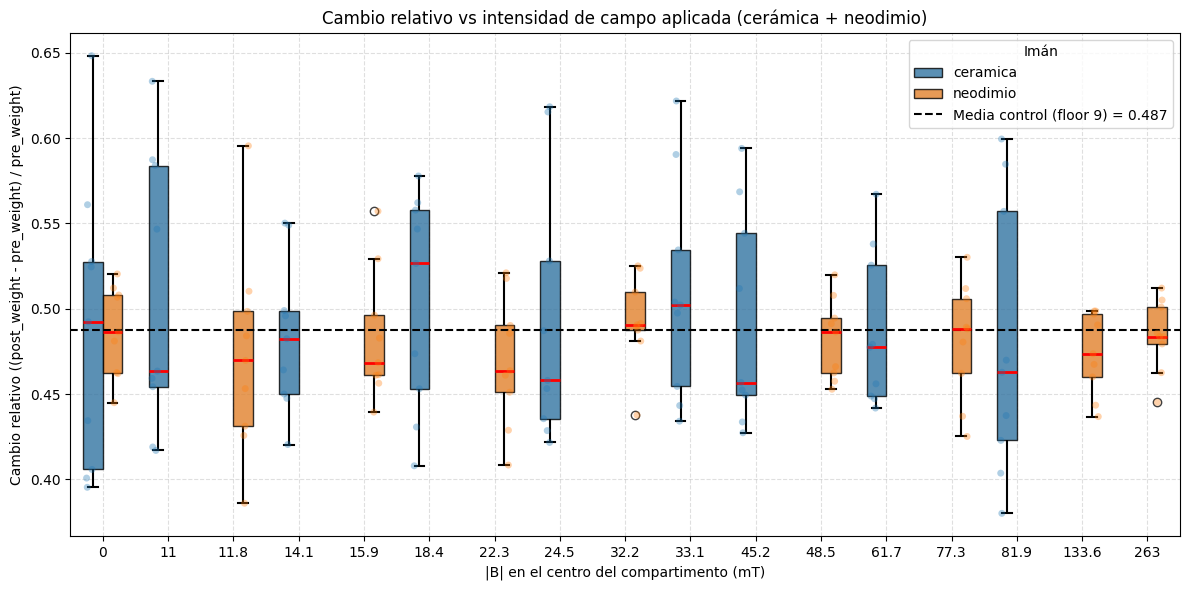

In [32]:
from pathlib import Path
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Todas las variables de esta celda usan el prefijo campo_ para no chocar
# con df/combined_df/fechas ya usados en celdas anteriores.
campo_experiments_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments")
campo_extra_dir = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/extra")

campo_fechas_por_iman = {
    "ceramica": ["20260608", "20260331", "20260622"],
    "neodimio": ["20260626", "20260721", "20260727"],
}
campo_control_floor = 9

campo_b_compart = {
    "ceramica": pd.read_csv(campo_extra_dir / "dosis_ceramica_compart.csv"),
    "neodimio": pd.read_csv(campo_extra_dir / "dosis_neodimio_compart.csv"),
}

campo_dfs = []
for iman, fechas_iman in campo_fechas_por_iman.items():
    b_iman = campo_b_compart[iman].copy()
    for fecha in fechas_iman:
        trays_path = campo_experiments_dir / fecha / "trays.csv"
        if not trays_path.exists():
            print(f"Advertencia: no se encontro {trays_path}")
            continue
        fecha_df = pd.read_csv(trays_path)
        fecha_df["iman"] = iman
        fecha_df["fecha"] = fecha
        campo_dfs.append(fecha_df)

campo_df = pd.concat(campo_dfs, ignore_index=True)
campo_df["treatment_floor"] = pd.to_numeric(campo_df["treatment_floor"], errors="coerce")
campo_df = campo_df.dropna(subset=["treatment_floor"])
campo_df["treatment_floor"] = campo_df["treatment_floor"].astype(int)
campo_df["pct_change"] = (campo_df["post_weight"] - campo_df["pre_weight"]) / campo_df["pre_weight"]

# Asigna B_compart_mT segun el imán y el nivel; el control (floor 9) no tiene
# fila en las tablas de dosis porque no recibe campo aplicado -> B = 0.
campo_b_lookup = pd.concat(
    [b_iman.assign(iman=iman) for iman, b_iman in campo_b_compart.items()],
    ignore_index=True,
).rename(columns={"nivel": "treatment_floor"})

campo_df = campo_df.merge(campo_b_lookup, on=["iman", "treatment_floor"], how="left")
campo_df.loc[campo_df["treatment_floor"] == campo_control_floor, "B_compart_mT"] = 0.0

campo_sin_b = campo_df[campo_df["B_compart_mT"].isna()]
if not campo_sin_b.empty:
    print("Filas sin B_compart_mT asignado (revisar treatment_floor fuera de 1-9):")
    print(campo_sin_b[["iman", "fecha", "treatment_floor"]].drop_duplicates())

campo_plot_df = campo_df.dropna(subset=["B_compart_mT"])
campo_b_order = sorted(campo_plot_df["B_compart_mT"].unique())

# Media del control (floor 9, B=0) combinando ambos imanes, como referencia.
campo_control_mean = campo_plot_df.loc[
    campo_plot_df["treatment_floor"] == campo_control_floor, "pct_change"
].mean()

plt.figure(figsize=(12, 6))
sns.boxplot(
    data=campo_plot_df,
    x="B_compart_mT",
    y="pct_change",
    hue="iman",
    order=campo_b_order,
    width=0.6,
    medianprops={"color": "red", "linewidth": 2},
    whiskerprops={"color": "k", "linewidth": 1.5},
    capprops={"color": "k", "linewidth": 1.5},
    boxprops={"alpha": 0.8, "edgecolor": "k"},
)
sns.stripplot(
    data=campo_plot_df,
    x="B_compart_mT",
    y="pct_change",
    hue="iman",
    order=campo_b_order,
    dodge=True,
    alpha=0.35,
    jitter=True,
    legend=False,
)

plt.axhline(
    campo_control_mean,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Media control (floor {campo_control_floor}) = {campo_control_mean:.3f}",
)

plt.xlabel("|B| en el centro del compartimento (mT)")
plt.ylabel("Cambio relativo ((post_weight - pre_weight) / pre_weight)")
plt.title("Cambio relativo vs intensidad de campo aplicada (cerámica + neodimio)")
plt.xticks(range(len(campo_b_order)), [f"{b:g}" for b in campo_b_order])
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Imán")
plt.tight_layout()
plt.show()

In [33]:
from statsmodels.formula.api import ols

# Regresion de dosis-respuesta: pct_change ~ B_compart_mT, controlando por iman.
# Usa campo_plot_df de la celda anterior (mismo prefijo campo_, sin pisar nada).
campo_modelo_base = ols("pct_change ~ B_compart_mT + C(iman)", data=campo_plot_df).fit()
print("Modelo: pct_change ~ B_compart_mT + C(iman)")
print(campo_modelo_base.summary())
print()

# Chequeo extra: pendiente distinta segun el iman (interaccion)
campo_modelo_interaccion = ols("pct_change ~ B_compart_mT * C(iman)", data=campo_plot_df).fit()
print("Modelo con interaccion: pct_change ~ B_compart_mT * C(iman)")
print(campo_modelo_interaccion.summary())

Modelo: pct_change ~ B_compart_mT + C(iman)
                            OLS Regression Results                            
Dep. Variable:             pct_change   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.004
Method:                 Least Squares   F-statistic:                     1.288
Date:                Fri, 25 Sep 2026   Prob (F-statistic):              0.279
Time:                        15:58:04   Log-Likelihood:                 248.85
No. Observations:                 162   AIC:                            -491.7
Df Residuals:                     159   BIC:                            -482.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------

In [34]:
# =============================================================================
# ANALISIS CONFIRMATORIO - preparacion de datos y modelo del peso
# Reemplaza al ANOVA/Tukey exploratorio de mas arriba. Decisiones clave:
#  - Unidad experimental = LA BANDEJA (nunca la semilla): n = 54.
#  - Diseno = bloques completos aleatorizados: cada fila (fecha x floor)
#    contiene los 9 tratamientos exactamente una vez -> bloque = fecha-floor.
#  - "Se analiza como se aleatorizo": el modelo lleva tratamiento + bloque.
#    position NO entra (F=1.19, p=0.34; gasta 8 gl y empeora el SE del
#    contraste). Se verifica como sensibilidad, no en el modelo principal.
#  - pct_change = (humedo 72h - seco inicial)/seco inicial: es IMBIBICION
#    (absorcion de agua), no biomasa. Nombrarlo asi en el texto.
# =============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests
from scipy import stats

CONF_EXPERIMENTS_DIR = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/experiments")
CONF_EXTRA_DIR = Path("/Users/kier/MEGA/tesina/tesis-magnetobiologia-software/data/extra")
CONF_FECHAS = ["20260804", "20260907"]      # replicas intercambiables (mismo protocolo)
CONF_DOSIS_CSV = "dosis_neodimio_compart.csv"
CONF_CONTROL_FLOOR = 9
CONF_N_SEMILLAS = 20
CONF_MARGEN_REL = 0.10                      # umbral de relevancia biologica: 10% relativo

conf_dfs = []
for conf_fecha in CONF_FECHAS:
    conf_path = CONF_EXPERIMENTS_DIR / conf_fecha / "trays.csv"
    if not conf_path.exists():
        print(f"Advertencia: no se encontro {conf_path}")
        continue
    conf_tmp = pd.read_csv(conf_path)
    conf_tmp.columns = conf_tmp.columns.str.strip()
    conf_tmp["fecha"] = conf_fecha
    conf_dfs.append(conf_tmp)

conf_df = pd.concat(conf_dfs, ignore_index=True)
conf_df["treatment_floor"] = pd.to_numeric(conf_df["treatment_floor"], errors="coerce")
conf_df = conf_df.dropna(subset=["treatment_floor", "pre_weight", "post_weight"]).copy()
conf_df["treatment_floor"] = conf_df["treatment_floor"].astype(int)
conf_df["position"] = conf_df["position"].astype(int)
conf_df["pct_change"] = (conf_df["post_weight"] - conf_df["pre_weight"]) / conf_df["pre_weight"]
conf_df["bloque"] = conf_df["fecha"] + "-" + conf_df["floor"].astype(str)
conf_df["con_iman"] = (conf_df["treatment_floor"] != CONF_CONTROL_FLOOR).astype(int)
# OJO: no_germinadas = semillas que NO germinaron (de 20). germinadas es el complemento.
conf_df["no_germinadas"] = pd.to_numeric(conf_df["no_germinadas"], errors="coerce")
conf_df["germinadas"] = CONF_N_SEMILLAS - conf_df["no_germinadas"]
conf_df["prop_germ"] = conf_df["germinadas"] / CONF_N_SEMILLAS

conf_dosis = pd.read_csv(CONF_EXTRA_DIR / CONF_DOSIS_CSV).rename(columns={"nivel": "treatment_floor"})
conf_df = conf_df.merge(conf_dosis, on="treatment_floor", how="left")
# El campo cae casi geometricamente (263 -> 11.8 mT), asi que la escala natural
# de dosis es log10(B): lineal en el numero de piso.
conf_df["log10_B"] = np.log10(conf_df["B_compart_mT"])

conf_tratados = conf_df[conf_df["con_iman"] == 1]
conf_media_control = conf_df.loc[conf_df["treatment_floor"] == CONF_CONTROL_FLOOR, "pct_change"].mean()
CONF_FORMULA_BLOQUE = " + C(bloque)"

print("=" * 72)
print("VERIFICACION DEL DISENO")
print("=" * 72)
conf_tab = pd.crosstab(conf_df["treatment_floor"], conf_df["bloque"])
print(conf_tab)
print(f"\nBloques completos y balanceados: {(conf_tab.values == 1).all()}")
print(f"n bandejas = {len(conf_df)} | control = {(conf_df.con_iman == 0).sum()} | tratadas = {(conf_df.con_iman == 1).sum()}")
print("LIMITACION: 1 sola bandeja de control por bloque contra 8 tratadas.")
print("Todo contraste contra el control apoya en n=6; es el cuello de botella de potencia.")

print("\n" + "=" * 72)
print(f"ENDPOINT 1: IMBIBICION A 72H  (media control = {conf_media_control:.4f})")
print("=" * 72)
conf_f_full = f"pct_change ~ C(treatment_floor, Treatment(reference={CONF_CONTROL_FLOOR})){CONF_FORMULA_BLOQUE}"
conf_m_full = smf.ols(conf_f_full, data=conf_df).fit()
print("Test global (omnibus) del tratamiento:")
print(anova_lm(conf_m_full, typ=2).round(5))

conf_pre = f"C(treatment_floor, Treatment(reference={CONF_CONTROL_FLOOR}))[T."
conf_ci = conf_m_full.conf_int()
conf_rows = []
for conf_term in conf_m_full.params.index:
    if conf_term.startswith(conf_pre):
        conf_fl = int(conf_term.split("T.")[1].rstrip("]"))
        conf_rows.append({
            "floor": conf_fl,
            "B_mT": float(conf_dosis.loc[conf_dosis.treatment_floor == conf_fl, "B_compart_mT"].iloc[0]),
            "diff": conf_m_full.params[conf_term],
            "ci_low": conf_ci.loc[conf_term, 0],
            "ci_high": conf_ci.loc[conf_term, 1],
            "p": conf_m_full.pvalues[conf_term],
        })
conf_vs_control = pd.DataFrame(conf_rows).sort_values("floor").reset_index(drop=True)
conf_vs_control["p_holm"] = multipletests(conf_vs_control["p"], method="holm")[1]
for conf_col, conf_src in [("dif_%", "diff"), ("ic_low_%", "ci_low"), ("ic_high_%", "ci_high")]:
    conf_vs_control[conf_col] = 100 * conf_vs_control[conf_src] / conf_media_control

print("\nCada piso vs control (piso 9), en % relativo a la media del control:")
print(conf_vs_control[["floor", "B_mT", "dif_%", "ic_low_%", "ic_high_%", "p", "p_holm"]]
      .round(3).to_string(index=False))

print("\n--- Contrastes de 1 grado de libertad (mas potentes que 8 comparaciones) ---")
conf_m_iman = smf.ols(f"pct_change ~ con_iman{CONF_FORMULA_BLOQUE}", data=conf_df).fit()
conf_est = conf_m_iman.params["con_iman"]
conf_se = conf_m_iman.bse["con_iman"]
conf_dfres = conf_m_iman.df_resid
conf_lo, conf_hi = conf_m_iman.conf_int().loc["con_iman"]
print(f"A) Cualquier iman vs control: {100*conf_est/conf_media_control:+.2f}% "
      f"IC95 [{100*conf_lo/conf_media_control:+.2f}%, {100*conf_hi/conf_media_control:+.2f}%] "
      f"p = {conf_m_iman.pvalues['con_iman']:.4f}")
conf_m_dosis = smf.ols(f"pct_change ~ log10_B{CONF_FORMULA_BLOQUE}", data=conf_tratados).fit()
print(f"B) Tendencia dosis-respuesta (pisos 1-8): {conf_m_dosis.params['log10_B']:+.5f} por decada de mT "
      f"p = {conf_m_dosis.pvalues['log10_B']:.4f}")

print("\n--- EQUIVALENCIA (TOST): no basta con 'p > 0.05' ---")
conf_delta = CONF_MARGEN_REL * conf_media_control
conf_p_tost = max(stats.t.sf((conf_est + conf_delta) / conf_se, conf_dfres),
                  stats.t.cdf((conf_est - conf_delta) / conf_se, conf_dfres))
conf_ic90 = conf_m_iman.conf_int(alpha=0.10).loc["con_iman"]
conf_mde = (stats.t.ppf(0.975, conf_dfres) + stats.t.ppf(0.80, conf_dfres)) * conf_se
print(f"Margen de relevancia: +-{CONF_MARGEN_REL:.0%} = +-{conf_delta:.5f}")
print(f"IC90 del efecto: [{conf_ic90[0]:+.5f}, {conf_ic90[1]:+.5f}]  p_TOST = {conf_p_tost:.5f}")
print(f"  -> {'EQUIVALENTE: el efecto es menor que el margen' if conf_p_tost < 0.05 else 'NO concluyente'}")
print(f"Efecto minimo detectable (80% potencia): {100*conf_mde/conf_media_control:.2f}% relativo")
conf_peor = conf_vs_control.loc[conf_vs_control[["ic_low_%", "ic_high_%"]].abs().max(axis=1).idxmax()]
print(f"Piso con el IC mas ancho: {int(conf_peor.floor)} -> [{conf_peor['ic_low_%']:+.1f}%, {conf_peor['ic_high_%']:+.1f}%]")

print("\n--- Supuestos y robustez ---")
print(f"Shapiro-Wilk sobre residuos: p = {stats.shapiro(conf_m_full.resid)[1]:.4f} (normalidad)")
print(f"Levene entre los 9 grupos:    p = {stats.levene(*[g['pct_change'].values for _, g in conf_df.groupby('treatment_floor')])[1]:.4f} (homocedasticidad)")
conf_cook = conf_m_full.get_influence().cooks_distance[0]
print(f"Cook D max = {conf_cook.max():.3f} (umbral 4/n = {4/len(conf_df):.3f}) -> "
      f"{(conf_cook > 4/len(conf_df)).sum()} bandejas influyentes, ninguna decisiva")
print("\nSensibilidad: el resultado no depende de las covariables elegidas.")
for conf_nombre, conf_extra in [("solo tratamiento", ""), ("+ bloque", " + C(bloque)"),
                                ("+ position", " + C(position)"), ("+ bloque + position", " + C(bloque) + C(position)")]:
    conf_ms = smf.ols(f"pct_change ~ con_iman{conf_extra}", data=conf_df).fit()
    print(f"  {conf_nombre:22s} efecto {100*conf_ms.params['con_iman']/conf_media_control:+.2f}% "
          f"SE {conf_ms.bse['con_iman']:.5f} p {conf_ms.pvalues['con_iman']:.4f}")

VERIFICACION DEL DISENO
bloque           20260804-A  20260804-B  20260804-C  20260907-A  20260907-B  \
treatment_floor                                                               
1                         1           1           1           1           1   
2                         1           1           1           1           1   
3                         1           1           1           1           1   
4                         1           1           1           1           1   
5                         1           1           1           1           1   
6                         1           1           1           1           1   
7                         1           1           1           1           1   
8                         1           1           1           1           1   
9                         1           1           1           1           1   

bloque           20260907-C  
treatment_floor              
1                         1  
2               

In [35]:
# =============================================================================
# ENDPOINT 2: GERMINACION  (requiere la celda anterior: conf_df)
# La germinacion es un RESULTADO del tratamiento por derecho propio, no una
# covariable del peso. Por eso va en su propio modelo.
# ADVERTENCIA METODOLOGICA: un GLM binomial sobre las 20 semillas de cada
# bandeja da p < 0.0001, pero es PSEUDO-REPLICACION: infla el n de 54 a 1080
# tratando semillas de la misma bandeja como independientes. La unidad
# aleatorizada es la bandeja, asi que se analiza la PROPORCION por bandeja.
# =============================================================================
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

gm_df = conf_df.dropna(subset=["germinadas"]).copy()
gm_tratados = gm_df[gm_df["con_iman"] == 1]

print("=" * 72)
print("ENDPOINT 2: GERMINACION (unidad = bandeja, n = %d)" % len(gm_df))
print("=" * 72)
print(gm_df.groupby("con_iman")["prop_germ"]
      .agg(["count", "mean", "std"]).rename(index={0: "control", 1: "con iman"}).round(3))
print("\nGerminadas de 20, por piso (piso 9 = control):")
print(gm_df.groupby("treatment_floor")
      .agg(media=("germinadas", "mean"), sd=("germinadas", "std"), n=("germinadas", "count"),
           B_mT=("B_compart_mT", "first")).round(2).to_string())

gm_m_iman = smf.ols("prop_germ ~ con_iman + C(bloque)", data=gm_df).fit()
gm_lo, gm_hi = gm_m_iman.conf_int().loc["con_iman"]
print(f"\nA) Cualquier iman vs control: {100*gm_m_iman.params['con_iman']:+.1f} puntos porcentuales "
      f"IC95 [{100*gm_lo:+.1f}, {100*gm_hi:+.1f}] p = {gm_m_iman.pvalues['con_iman']:.4f}")

gm_m_dosis = smf.ols("prop_germ ~ log10_B + C(bloque)", data=gm_tratados).fit()
gm_obs = gm_m_dosis.params["log10_B"]
print(f"B) Tendencia dosis (pisos 1-8): {100*gm_obs:+.1f} pp por decada de mT "
      f"p = {gm_m_dosis.pvalues['log10_B']:.4f}")

# Test de permutacion: no asume normalidad de una proporcion sobre 20 semillas.
# Permuta la dosis DENTRO de cada bloque, replicando la aleatorizacion real.
GM_N_PERM = 5000
gm_rng = np.random.default_rng(0)
gm_perm = gm_tratados.copy()
gm_extremos = 0
for _ in range(GM_N_PERM):
    gm_perm["log10_B"] = gm_perm.groupby("bloque")["log10_B"].transform(
        lambda s: gm_rng.permutation(s.values))
    gm_coef = smf.ols("prop_germ ~ log10_B + C(bloque)", data=gm_perm).fit().params["log10_B"]
    gm_extremos += abs(gm_coef) >= abs(gm_obs)
gm_p_perm = (gm_extremos + 1) / (GM_N_PERM + 1)
print(f"   p por permutacion dentro de bloque ({GM_N_PERM} remuestreos): {gm_p_perm:.4f}")

print("\nLECTURA HONESTA:")
print("  Los dos extremos de campo coinciden con el control (~13.5/20) mientras los")
print("  pisos intermedios llegan a ~16.5/20: compatible con una ventana de dosis,")
print("  pero ninguno de los dos contrastes alcanza significancia. Con 6 bandejas")
print("  de control no se puede resolver. Es una hipotesis a testear, no un hallazgo.")

print("\n" + "=" * 72)
print("SENSIBILIDAD (NO es el analisis principal)")
print("=" * 72)
print("Ajustar el peso por no_germinadas condiciona sobre una variable POSTERIOR")
print("al tratamiento: si el iman afecta la germinacion, el coeficiente deja de ser")
print("el efecto causal total (sesgo de mediador). Se reporta solo como contraste.")
sens_m = smf.ols("pct_change ~ con_iman + no_germinadas + C(bloque)", data=gm_df).fit()
sens_base = smf.ols("pct_change ~ con_iman + C(bloque)", data=gm_df).fit()
print(f"  sin ajustar : {100*sens_base.params['con_iman']/conf_media_control:+.2f}% "
      f"p = {sens_base.pvalues['con_iman']:.4f}  (sigma {np.sqrt(sens_base.scale):.5f})")
print(f"  ajustado    : {100*sens_m.params['con_iman']/conf_media_control:+.2f}% "
      f"p = {sens_m.pvalues['con_iman']:.4f}  (sigma {np.sqrt(sens_m.scale):.5f})")
print(f"  no_germinadas sobre el peso: {sens_m.params['no_germinadas']:+.5f} por semilla fallida "
      f"p = {sens_m.pvalues['no_germinadas']:.2g}")
print("  Nota: la germinacion predice fuertemente el peso (era esperable: una semilla")
print("  germinada retiene mas agua), pero eso no cambia la conclusion sobre el iman.")

ENDPOINT 2: GERMINACION (unidad = bandeja, n = 54)
          count   mean    std
con_iman                     
control       6  0.675  0.088
con iman     48  0.775  0.114

Germinadas de 20, por piso (piso 9 = control):
                 media    sd  n   B_mT
treatment_floor                       
1                13.50  2.43  6  263.0
2                16.33  1.97  6  133.6
3                15.00  3.10  6   77.3
4                16.00  1.79  6   48.5
5                14.33  1.75  6   32.2
6                16.50  1.87  6   22.3
7                16.33  1.37  6   15.9
8                16.00  2.76  6   11.8
9                13.50  1.76  6    NaN

A) Cualquier iman vs control: +10.0 puntos porcentuales IC95 [-0.0, +20.0] p = 0.0500
B) Tendencia dosis (pisos 1-8): -6.7 pp por decada de mT p = 0.0844
   p por permutacion dentro de bloque (5000 remuestreos): 0.0838

LECTURA HONESTA:
  Los dos extremos de campo coinciden con el control (~13.5/20) mientras los
  pisos intermedios llegan a ~16.5/20

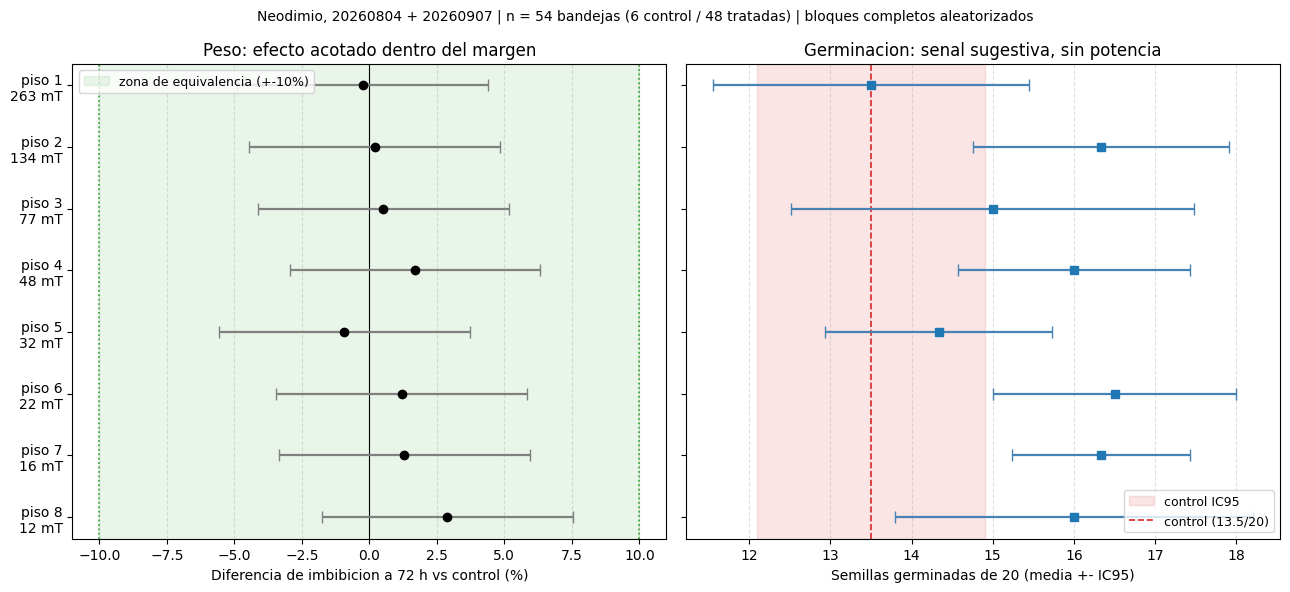

In [36]:
# =============================================================================
# FIGURA: forest plot con banda de equivalencia (requiere las 2 celdas previas)
# Comunica el resultado nulo correctamente: no "no hay diferencias", sino
# "el efecto esta acotado dentro del margen de relevancia".
# =============================================================================
import matplotlib.pyplot as plt

fig, (ax_peso, ax_gm) = plt.subplots(1, 2, figsize=(13, 6), sharey=True)

ax_peso.axvspan(-100 * CONF_MARGEN_REL, 100 * CONF_MARGEN_REL, color="tab:green", alpha=0.10,
                label=f"zona de equivalencia (+-{CONF_MARGEN_REL:.0%})")
ax_peso.axvline(0, color="black", linestyle="-", linewidth=0.8)
for conf_signo in (-1, 1):
    ax_peso.axvline(conf_signo * 100 * CONF_MARGEN_REL, color="tab:green", linestyle=":", linewidth=1.2)
ax_peso.errorbar(conf_vs_control["dif_%"], conf_vs_control["floor"],
                 xerr=[conf_vs_control["dif_%"] - conf_vs_control["ic_low_%"],
                       conf_vs_control["ic_high_%"] - conf_vs_control["dif_%"]],
                 fmt="o", color="black", ecolor="gray", elinewidth=1.6, capsize=4, markersize=6)
ax_peso.set_yticks(conf_vs_control["floor"])
ax_peso.set_yticklabels([f"piso {int(f)}\n{b:.0f} mT"
                         for f, b in zip(conf_vs_control["floor"], conf_vs_control["B_mT"])])
ax_peso.invert_yaxis()
ax_peso.set_xlabel("Diferencia de imbibicion a 72 h vs control (%)")
ax_peso.set_title("Peso: efecto acotado dentro del margen")
ax_peso.grid(True, axis="x", linestyle="--", alpha=0.4)
ax_peso.legend(loc="upper left", fontsize=9)

gm_plot = (gm_df[gm_df["con_iman"] == 1]
             .groupby("treatment_floor")
             .agg(media=("germinadas", "mean"), sd=("germinadas", "std"), n=("germinadas", "count"))
             .reset_index())
gm_plot["ee"] = gm_plot["sd"] / gm_plot["n"] ** 0.5
gm_ctrl = gm_df[gm_df["con_iman"] == 0]["germinadas"]
gm_ctrl_ee = gm_ctrl.std() / len(gm_ctrl) ** 0.5
ax_gm.axvspan(gm_ctrl.mean() - 1.96 * gm_ctrl_ee, gm_ctrl.mean() + 1.96 * gm_ctrl_ee,
                color="tab:red", alpha=0.12, label="control IC95")
ax_gm.axvline(gm_ctrl.mean(), color="tab:red", linestyle="--", linewidth=1.2,
                label=f"control ({gm_ctrl.mean():.1f}/20)")
ax_gm.errorbar(gm_plot["media"], gm_plot["treatment_floor"],
                 xerr=1.96 * gm_plot["ee"], fmt="s", color="tab:blue", ecolor="steelblue",
                 elinewidth=1.6, capsize=4, markersize=6)
ax_gm.set_xlabel("Semillas germinadas de 20 (media +- IC95)")
ax_gm.set_title("Germinacion: senal sugestiva, sin potencia")
ax_gm.grid(True, axis="x", linestyle="--", alpha=0.4)
ax_gm.legend(loc="lower right", fontsize=9)

fig.suptitle(f"Neodimio, {' + '.join(CONF_FECHAS)} | n = {len(conf_df)} bandejas "
             f"(6 control / 48 tratadas) | bloques completos aleatorizados", fontsize=10)
fig.tight_layout()
plt.show()

/var/folders/ll/hm35mj650fs_spb22x5qqnqh0000gn/T/ipykernel_5190/3122454749.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=box_df, x="treatment_floor", y="germinadas", order=box_orden,
/var/folders/ll/hm35mj650fs_spb22x5qqnqh0000gn/T/ipykernel_5190/3122454749.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_box.set_xticklabels([f"{f}\n{'sin campo' if f == CONF_CONTROL_FLOOR else format(box_df.loc[box_df.treatment_floor == f, 'B_compart_mT'].iloc[0], '.0f') + ' mT'}"


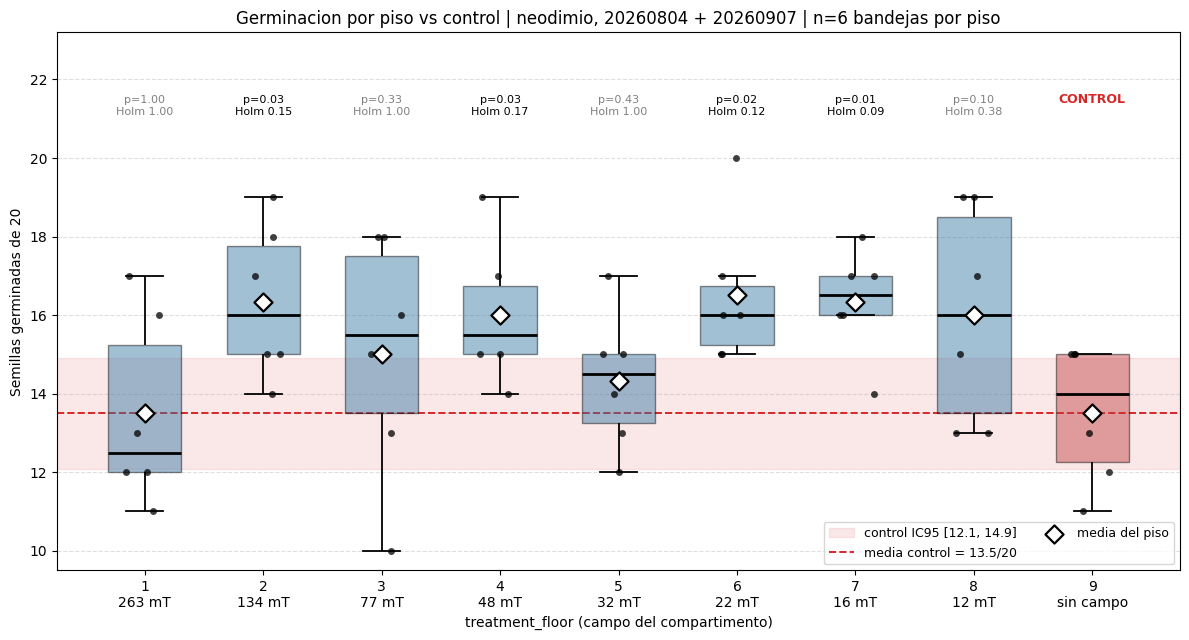

Germinadas de 20 por piso (piso 9 = control, sin campo):
                  B_mT   media  mediana     sd  min  max  n  dif_vs_control  p_welch  p_holm
treatment_floor                                                                             
1                263.0  13.500     12.5  2.429   11   17  6           0.000    1.000   1.000
2                133.6  16.333     16.0  1.966   14   19  6           2.833    0.025   0.153
3                 77.3  15.000     15.5  3.098   10   18  6           1.500    0.333   0.999
4                 48.5  16.000     15.5  1.789   14   19  6           2.500    0.035   0.174
5                 32.2  14.333     14.5  1.751   12   17  6           0.833    0.430   0.999
6                 22.3  16.500     16.0  1.871   15   20  6           3.000    0.017   0.119
7                 15.9  16.333     16.5  1.366   14   18  6           2.833    0.012   0.094
8                 11.8  16.000     16.0  2.757   13   19  6           2.500    0.096   0.384
9            

In [37]:
# =============================================================================
# FIGURA: germinacion por treatment_floor, 1-8 contra el control (piso 9)
# Requiere las celdas de analisis previas (conf_df / gm_df).
# Con n=6 por grupo un boxplot solo puede enganar: se superponen las 6
# bandejas individuales para que se vea la dispersion real.
# =============================================================================
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

box_df = gm_df.copy()
box_orden = [f for f in range(1, CONF_CONTROL_FLOOR + 1) if f in set(box_df["treatment_floor"])]
box_ctrl = box_df.loc[box_df["treatment_floor"] == CONF_CONTROL_FLOOR, "germinadas"]
box_ctrl_ee = box_ctrl.std() / np.sqrt(len(box_ctrl))
box_colores = ["tab:red" if f == CONF_CONTROL_FLOOR else "tab:blue" for f in box_orden]

fig_box, ax_box = plt.subplots(figsize=(12, 6.5))

# Banda de referencia del control: IC95 de su media
ax_box.axhspan(box_ctrl.mean() - 1.96 * box_ctrl_ee, box_ctrl.mean() + 1.96 * box_ctrl_ee,
               color="tab:red", alpha=0.10, zorder=0,
               label=f"control IC95 [{box_ctrl.mean() - 1.96 * box_ctrl_ee:.1f}, {box_ctrl.mean() + 1.96 * box_ctrl_ee:.1f}]")
ax_box.axhline(box_ctrl.mean(), color="tab:red", linestyle="--", linewidth=1.4, zorder=1,
               label=f"media control = {box_ctrl.mean():.1f}/20")

sns.boxplot(data=box_df, x="treatment_floor", y="germinadas", order=box_orden,
            palette=box_colores, width=0.62, showfliers=False, ax=ax_box,
            medianprops={"color": "black", "linewidth": 2},
            boxprops={"alpha": 0.45, "edgecolor": "k"},
            whiskerprops={"color": "k", "linewidth": 1.3},
            capprops={"color": "k", "linewidth": 1.3})
sns.stripplot(data=box_df, x="treatment_floor", y="germinadas", order=box_orden,
              color="black", size=5, jitter=0.18, alpha=0.75, ax=ax_box, zorder=5)

# Media de cada piso (rombo blanco), para no leer solo la mediana con n=6
box_medias = box_df.groupby("treatment_floor")["germinadas"].mean().reindex(box_orden)
ax_box.scatter(range(len(box_orden)), box_medias.values, marker="D", s=85,
               facecolors="white", edgecolors="black", linewidths=1.6, zorder=10,
               label="media del piso")

# p de cada piso vs control (Welch), sin corregir y con Holm: n=6 vs n=6
from scipy import stats as box_stats
from statsmodels.stats.multitest import multipletests as box_multi
box_p = []
for box_f in box_orden:
    if box_f == CONF_CONTROL_FLOOR:
        box_p.append(np.nan)
        continue
    box_p.append(box_stats.ttest_ind(
        box_df.loc[box_df.treatment_floor == box_f, "germinadas"], box_ctrl, equal_var=False).pvalue)
box_validos = [i for i, p in enumerate(box_p) if not np.isnan(p)]
box_p_holm = np.full(len(box_p), np.nan)
box_p_holm[box_validos] = box_multi([box_p[i] for i in box_validos], method="holm")[1]

box_top = box_df["germinadas"].max()
for box_i, box_f in enumerate(box_orden):
    if box_f == CONF_CONTROL_FLOOR:
        ax_box.text(box_i, box_top + 1.4, "CONTROL", ha="center", fontsize=9,
                    color="tab:red", fontweight="bold")
        continue
    ax_box.text(box_i, box_top + 1.1, f"p={box_p[box_i]:.2f}\nHolm {box_p_holm[box_i]:.2f}",
                ha="center", fontsize=8,
                color="black" if box_p[box_i] < 0.05 else "gray")

ax_box.set_xticklabels([f"{f}\n{'sin campo' if f == CONF_CONTROL_FLOOR else format(box_df.loc[box_df.treatment_floor == f, 'B_compart_mT'].iloc[0], '.0f') + ' mT'}"
                        for f in box_orden])
ax_box.set_xlabel("treatment_floor (campo del compartimento)")
ax_box.set_ylabel("Semillas germinadas de 20")
ax_box.set_ylim(top=box_top + 3.2)
ax_box.set_title(f"Germinacion por piso vs control | neodimio, {' + '.join(CONF_FECHAS)} | n=6 bandejas por piso")
ax_box.grid(True, axis="y", linestyle="--", alpha=0.4)
ax_box.legend(loc="lower right", fontsize=9, ncol=2)
fig_box.tight_layout()
plt.show()

print("Germinadas de 20 por piso (piso 9 = control, sin campo):")
box_tabla = (box_df.groupby("treatment_floor")
             .agg(B_mT=("B_compart_mT", "first"), media=("germinadas", "mean"),
                  mediana=("germinadas", "median"), sd=("germinadas", "std"),
                  min=("germinadas", "min"), max=("germinadas", "max"), n=("germinadas", "count")))
box_tabla["dif_vs_control"] = box_tabla["media"] - box_ctrl.mean()
box_tabla["p_welch"] = box_p
box_tabla["p_holm"] = box_p_holm
print(box_tabla.round(3).to_string())
print("\nNinguna comparacion individual sobrevive la correccion por multiplicidad:")
print("con 6 bandejas por grupo solo se detectarian diferencias enormes (>4 semillas de 20).")

ENDPOINT 3: LARGO DE RADICULA (unidad = bandeja)
Raices medidas por bandeja, por fecha:
          count  min   50%    max
fecha                            
20260804   27.0  0.0  65.0  132.0
20260907   27.0  0.0   5.0   12.0
20260911   27.0  9.0  20.0  157.0

Excluidas (< 3 raices medidas):
    tray_id  treatment_floor  n_raices
20260804_B4                3         0
20260804_B7                7         0
20260804_B9                9         0
20260907_B6                7         0
20260907_B7                9         2
20260907_C2                3         1

Marcadas como probable sobre-segmentacion (> 3x la mediana de su fecha);
se mantienen en el analisis principal y se quitan en la sensibilidad:
    tray_id  treatment_floor  n_raices  mediana_mm
20260911_C7                7       157        3.24

n bandejas = 75 | bandejas por piso: {1: 9, 2: 9, 3: 7, 4: 9, 5: 9, 6: 9, 7: 7, 8: 9, 9: 7}
Bloques completos: False (si falta alguna bandeja el modelo con bloque lo absorbe)

Mediana por b

/var/folders/ll/hm35mj650fs_spb22x5qqnqh0000gn/T/ipykernel_5190/222951770.py:154: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=rl_df, x="treatment_floor", y="mediana_mm", order=rl_orden,
/var/folders/ll/hm35mj650fs_spb22x5qqnqh0000gn/T/ipykernel_5190/222951770.py:180: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_rl.set_xticklabels([f"{f}\n{'sin campo' if f == CONF_CONTROL_FLOOR else format(rl_df.loc[rl_df.treatment_floor == f, 'B_compart_mT'].iloc[0], '.0f') + ' mT'}"


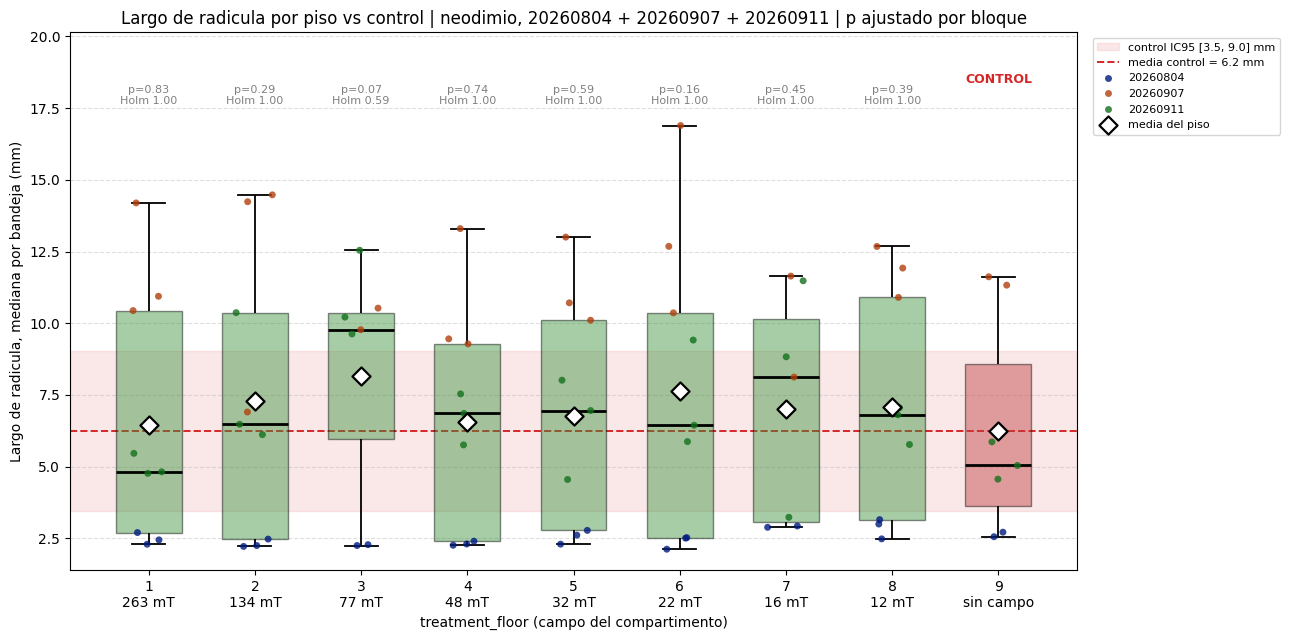

Mediana del largo por bandeja, resumida por piso (piso 9 = control):
                  B_mT  media     sd    min     max  n_bandejas  raices_tot  dif_vs_control  p_bloque  p_holm
treatment_floor                                                                                              
1                263.0  6.454  4.328  2.297  14.195           9         243           0.211     0.835   1.000
2                133.6  7.282  4.820  2.221  14.477           9         236           1.039     0.293   1.000
3                 77.3  8.175  4.149  2.253  12.546           7         172           1.932     0.073   0.587
4                 48.5  6.574  3.820  2.263  13.300           9         301           0.331     0.740   1.000
5                 32.2  6.782  3.956  2.300  13.004           9         378           0.540     0.586   1.000
6                 22.3  7.648  5.112  2.124  16.893           9         305           1.405     0.156   1.000
7                 15.9  7.020  3.955  2.888  11.644

In [38]:
# =============================================================================
# ENDPOINT 3: LARGO DE RADICULA  (requiere la celda de analisis confirmatorio:
# CONF_EXPERIMENTS_DIR, CONF_EXTRA_DIR, CONF_DOSIS_CSV, CONF_CONTROL_FLOOR)
#  - Unidad experimental = LA BANDEJA. Las raices de una misma bandeja no son
#    independientes: analizarlas sueltas seria pseudo-replicacion.
#  - Endpoint principal = MEDIANA del largo por bandeja: la segmentacion a veces
#    parte una radicula en varios fragmentos (hay bandejas con >100 objetos para
#    20 semillas) y la mediana es mucho menos sensible a eso que la media.
#  - Diseno igual que el peso: bloque = fecha-floor, modelo tratamiento + bloque.
# =============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multitest import multipletests

RL_FECHAS = ["20260804", "20260907", "20260911"]
RL_MIN_RAICES = 3          # bandejas con menos raices medidas no dan una mediana confiable
RL_FACTOR_SOSPECHA = 3     # n_raices > 3x la mediana de su fecha -> probable sobre-segmentacion

rl_raices = []
for rl_fecha in RL_FECHAS:
    rl_path = CONF_EXPERIMENTS_DIR / rl_fecha / "processed" / "root_lengths.csv"
    if not rl_path.exists():
        print(f"Advertencia: no se encontro {rl_path}")
        continue
    rl_tmp = pd.read_csv(rl_path)
    rl_tmp["fecha"] = rl_fecha
    rl_raices.append(rl_tmp)
rl_raices = pd.concat(rl_raices, ignore_index=True)

rl_trays = []
for rl_fecha in RL_FECHAS:
    rl_tmp = pd.read_csv(CONF_EXPERIMENTS_DIR / rl_fecha / "trays.csv")
    rl_tmp.columns = rl_tmp.columns.str.strip()
    rl_tmp["fecha"] = rl_fecha
    rl_trays.append(rl_tmp[["tray_id", "fecha", "treatment_floor", "floor", "position"]])
rl_trays = pd.concat(rl_trays, ignore_index=True)
rl_trays["treatment_floor"] = pd.to_numeric(rl_trays["treatment_floor"], errors="coerce")
rl_trays = rl_trays.dropna(subset=["treatment_floor"])
rl_trays["treatment_floor"] = rl_trays["treatment_floor"].astype(int)
rl_trays["bloque"] = rl_trays["fecha"] + "-" + rl_trays["floor"].astype(str)
rl_trays["con_iman"] = (rl_trays["treatment_floor"] != CONF_CONTROL_FLOOR).astype(int)
rl_dosis = pd.read_csv(CONF_EXTRA_DIR / CONF_DOSIS_CSV).rename(columns={"nivel": "treatment_floor"})
rl_trays = rl_trays.merge(rl_dosis, on="treatment_floor", how="left")
rl_trays["log10_B"] = np.log10(rl_trays["B_compart_mT"])

# Resumen por bandeja (left join: las bandejas sin ninguna raiz quedan con n=0)
rl_por_bandeja = (rl_raices.groupby("tray_id")["length_mm"]
                  .agg(mediana_mm="median", media_mm="mean", n_raices="count").reset_index())
rl_df = rl_trays.merge(rl_por_bandeja, on="tray_id", how="left")
rl_df["n_raices"] = rl_df["n_raices"].fillna(0).astype(int)
rl_df["sospechosa"] = rl_df["n_raices"] > RL_FACTOR_SOSPECHA * rl_df.groupby("fecha")["n_raices"].transform("median")

print("=" * 72)
print("ENDPOINT 3: LARGO DE RADICULA (unidad = bandeja)")
print("=" * 72)
print("Raices medidas por bandeja, por fecha:")
print(rl_df.groupby("fecha")["n_raices"].describe()[["count", "min", "50%", "max"]].to_string())
rl_excluidas = rl_df[rl_df["n_raices"] < RL_MIN_RAICES]
if len(rl_excluidas):
    print(f"\nExcluidas (< {RL_MIN_RAICES} raices medidas):")
    print(rl_excluidas[["tray_id", "treatment_floor", "n_raices"]].to_string(index=False))
rl_df = rl_df[rl_df["n_raices"] >= RL_MIN_RAICES].copy()
if rl_df["sospechosa"].any():
    print(f"\nMarcadas como probable sobre-segmentacion (> {RL_FACTOR_SOSPECHA}x la mediana de su fecha);")
    print("se mantienen en el analisis principal y se quitan en la sensibilidad:")
    print(rl_df.loc[rl_df["sospechosa"], ["tray_id", "treatment_floor", "n_raices", "mediana_mm"]]
          .round(2).to_string(index=False))

rl_tab = pd.crosstab(rl_df["treatment_floor"], rl_df["bloque"])
print(f"\nn bandejas = {len(rl_df)} | bandejas por piso: {rl_tab.sum(axis=1).to_dict()}")
print(f"Bloques completos: {(rl_tab.values == 1).all()} (si falta alguna bandeja el modelo con bloque lo absorbe)")

rl_media_control = rl_df.loc[rl_df["treatment_floor"] == CONF_CONTROL_FLOOR, "mediana_mm"].mean()
print(f"\nMediana por bandeja, media del control = {rl_media_control:.2f} mm")
print("Diferencias entre fechas (el bloque las absorbe):")
print(rl_df.groupby("fecha")["mediana_mm"].agg(["count", "mean", "std"]).round(2).to_string())

rl_f_full = f"mediana_mm ~ C(treatment_floor, Treatment(reference={CONF_CONTROL_FLOOR})) + C(bloque)"
rl_m_full = smf.ols(rl_f_full, data=rl_df).fit()
print("\nTest global (omnibus) del tratamiento:")
print(anova_lm(rl_m_full, typ=2).round(5))

rl_pre = f"C(treatment_floor, Treatment(reference={CONF_CONTROL_FLOOR}))[T."
rl_ci = rl_m_full.conf_int()
rl_rows = []
for rl_term in rl_m_full.params.index:
    if rl_term.startswith(rl_pre):
        rl_fl = int(rl_term.split("T.")[1].rstrip("]"))
        rl_rows.append({
            "floor": rl_fl,
            "B_mT": float(rl_dosis.loc[rl_dosis.treatment_floor == rl_fl, "B_compart_mT"].iloc[0]),
            "diff_mm": rl_m_full.params[rl_term],
            "ci_low": rl_ci.loc[rl_term, 0],
            "ci_high": rl_ci.loc[rl_term, 1],
            "p": rl_m_full.pvalues[rl_term],
        })
rl_vs_control = pd.DataFrame(rl_rows).sort_values("floor").reset_index(drop=True)
rl_vs_control["p_holm"] = multipletests(rl_vs_control["p"], method="holm")[1]
for rl_col, rl_src in [("dif_%", "diff_mm"), ("ic_low_%", "ci_low"), ("ic_high_%", "ci_high")]:
    rl_vs_control[rl_col] = 100 * rl_vs_control[rl_src] / rl_media_control
print("\nCada piso vs control (piso 9), ajustado por bloque, en % relativo al control:")
print(rl_vs_control[["floor", "B_mT", "diff_mm", "dif_%", "ic_low_%", "ic_high_%", "p", "p_holm"]]
      .round(3).to_string(index=False))

print("\n--- Contrastes de 1 grado de libertad ---")
rl_m_iman = smf.ols("mediana_mm ~ con_iman + C(bloque)", data=rl_df).fit()
rl_est = rl_m_iman.params["con_iman"]
rl_lo, rl_hi = rl_m_iman.conf_int().loc["con_iman"]
print(f"A) Cualquier iman vs control: {rl_est:+.2f} mm ({100*rl_est/rl_media_control:+.1f}%) "
      f"IC95 [{100*rl_lo/rl_media_control:+.1f}%, {100*rl_hi/rl_media_control:+.1f}%] "
      f"p = {rl_m_iman.pvalues['con_iman']:.4f}")
rl_m_dosis = smf.ols("mediana_mm ~ log10_B + C(bloque)", data=rl_df[rl_df["con_iman"] == 1]).fit()
print(f"B) Tendencia dosis-respuesta (pisos 1-8): {rl_m_dosis.params['log10_B']:+.2f} mm por decada de mT "
      f"p = {rl_m_dosis.pvalues['log10_B']:.4f}")
rl_mde = (stats.t.ppf(0.975, rl_m_iman.df_resid) + stats.t.ppf(0.80, rl_m_iman.df_resid)) * rl_m_iman.bse["con_iman"]
print(f"Efecto minimo detectable en A) (80% potencia): {rl_mde:.2f} mm = {100*rl_mde/rl_media_control:.1f}% relativo")

print("\n--- Supuestos ---")
print(f"Shapiro-Wilk sobre residuos: p = {stats.shapiro(rl_m_full.resid)[1]:.4f} (normalidad)")
print(f"Levene entre los 9 grupos:    p = {stats.levene(*[g['mediana_mm'].values for _, g in rl_df.groupby('treatment_floor')])[1]:.4f} (homocedasticidad)")

print("\n--- Sensibilidad del contraste A) ---")
rl_sens = [("mediana por bandeja (principal)", rl_df, "mediana_mm"),
           ("media por bandeja", rl_df, "media_mm"),
           ("sin bandejas sospechosas", rl_df[~rl_df["sospechosa"]], "mediana_mm")]
for rl_nombre, rl_data, rl_y in rl_sens:
    rl_ms = smf.ols(f"{rl_y} ~ con_iman + C(bloque)", data=rl_data).fit()
    print(f"  {rl_nombre:32s} {rl_ms.params['con_iman']:+.2f} mm  p = {rl_ms.pvalues['con_iman']:.4f}  (n={len(rl_data)})")
# Modelo mixto a nivel raiz: usa todas las raices, pero con intercepto aleatorio
# por bandeja, asi que la unidad efectiva sigue siendo la bandeja.
rl_raiz = rl_raices.merge(rl_df[["tray_id", "con_iman", "bloque"]], on="tray_id", how="inner")
rl_mm = smf.mixedlm("length_mm ~ con_iman + C(bloque)", data=rl_raiz, groups=rl_raiz["tray_id"]).fit()
print(f"  {'mixto a nivel raiz (1|bandeja)':32s} {rl_mm.params['con_iman']:+.2f} mm  p = {rl_mm.pvalues['con_iman']:.4f}  (n={len(rl_raiz)} raices)")

# -----------------------------------------------------------------------------
# FIGURA: mediana por bandeja, pisos 1-8 contra el control (piso 9)
# -----------------------------------------------------------------------------
rl_orden = [f for f in range(1, CONF_CONTROL_FLOOR + 1) if f in set(rl_df["treatment_floor"])]
rl_ctrl = rl_df.loc[rl_df["treatment_floor"] == CONF_CONTROL_FLOOR, "mediana_mm"]
rl_ctrl_ee = rl_ctrl.std() / np.sqrt(len(rl_ctrl))
rl_colores = ["tab:red" if f == CONF_CONTROL_FLOOR else "tab:green" for f in rl_orden]

fig_rl, ax_rl = plt.subplots(figsize=(13, 6.5))
ax_rl.axhspan(rl_ctrl.mean() - 1.96 * rl_ctrl_ee, rl_ctrl.mean() + 1.96 * rl_ctrl_ee,
              color="tab:red", alpha=0.10, zorder=0,
              label=f"control IC95 [{rl_ctrl.mean() - 1.96 * rl_ctrl_ee:.1f}, {rl_ctrl.mean() + 1.96 * rl_ctrl_ee:.1f}] mm")
ax_rl.axhline(rl_ctrl.mean(), color="tab:red", linestyle="--", linewidth=1.4, zorder=1,
              label=f"media control = {rl_ctrl.mean():.1f} mm")
sns.boxplot(data=rl_df, x="treatment_floor", y="mediana_mm", order=rl_orden,
            palette=rl_colores, width=0.62, showfliers=False, ax=ax_rl,
            medianprops={"color": "black", "linewidth": 2},
            boxprops={"alpha": 0.45, "edgecolor": "k"},
            whiskerprops={"color": "k", "linewidth": 1.3},
            capprops={"color": "k", "linewidth": 1.3})
sns.stripplot(data=rl_df, x="treatment_floor", y="mediana_mm", order=rl_orden, hue="fecha",
              palette="dark", size=5, jitter=0.18, alpha=0.8, ax=ax_rl, zorder=5)
rl_medias = rl_df.groupby("treatment_floor")["mediana_mm"].mean().reindex(rl_orden)
ax_rl.scatter(range(len(rl_orden)), rl_medias.values, marker="D", s=85,
              facecolors="white", edgecolors="black", linewidths=1.6, zorder=10,
              label="media del piso")

# Anotacion: p del modelo con bloque (el mismo de la tabla), sin corregir y Holm
rl_p_map = rl_vs_control.set_index("floor")[["p", "p_holm"]]
rl_top = rl_df["mediana_mm"].max()
rl_rango = rl_top - rl_df["mediana_mm"].min()
for rl_i, rl_f in enumerate(rl_orden):
    if rl_f == CONF_CONTROL_FLOOR:
        ax_rl.text(rl_i, rl_top + 0.10 * rl_rango, "CONTROL", ha="center", fontsize=9,
                   color="tab:red", fontweight="bold")
        continue
    rl_p, rl_ph = rl_p_map.loc[rl_f]
    ax_rl.text(rl_i, rl_top + 0.05 * rl_rango, f"p={rl_p:.2f}\nHolm {rl_ph:.2f}",
               ha="center", fontsize=8, color="black" if rl_p < 0.05 else "gray")

ax_rl.set_xticklabels([f"{f}\n{'sin campo' if f == CONF_CONTROL_FLOOR else format(rl_df.loc[rl_df.treatment_floor == f, 'B_compart_mT'].iloc[0], '.0f') + ' mT'}"
                       for f in rl_orden])
ax_rl.set_xlabel("treatment_floor (campo del compartimento)")
ax_rl.set_ylabel("Largo de radicula, mediana por bandeja (mm)")
ax_rl.set_ylim(top=rl_top + 0.22 * rl_rango)
ax_rl.set_title(f"Largo de radicula por piso vs control | neodimio, {' + '.join(RL_FECHAS)} | p ajustado por bloque")
ax_rl.grid(True, axis="y", linestyle="--", alpha=0.4)
ax_rl.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
fig_rl.tight_layout()
plt.show()

print("Mediana del largo por bandeja, resumida por piso (piso 9 = control):")
rl_tabla = (rl_df.groupby("treatment_floor")
            .agg(B_mT=("B_compart_mT", "first"), media=("mediana_mm", "mean"),
                 sd=("mediana_mm", "std"), min=("mediana_mm", "min"), max=("mediana_mm", "max"),
                 n_bandejas=("mediana_mm", "count"), raices_tot=("n_raices", "sum")))
rl_tabla["dif_vs_control"] = rl_tabla["media"] - rl_ctrl.mean()
rl_tabla = rl_tabla.join(rl_p_map.rename(columns={"p": "p_bloque", "p_holm": "p_holm"}))
print(rl_tabla.round(3).to_string())
